# 6장 1강: 전이학습의 기본 원리 — 실습문제 풀이

> **풀이 기준**: 프로젝트에 업로드된 `전기사용량.csv`(204,000행 × 10열)와 `building_info.csv`(100행 × 7열)로 코드를 실제 실행한 결과입니다. 노트북의 파일 찾기 함수가 괄호 없는 파일 이름도 읽으므로 그대로 사용했습니다.
>
> **가정한 내용**: 별도 판단이 필요한 부분은 없었습니다. 제공 함수·시드·학습률·epoch를 그대로 사용했습니다. 그래프 축 이름은 한글 글꼴 문제를 피하려고 영어로 표기했습니다.

---

## 공통 준비 코드 (제공 코드)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_file(names):
    for name in names:
        if Path(name).exists():
            return Path(name)
    raise FileNotFoundError("노트북과 같은 폴더에 파일을 넣어 주세요: " + ", ".join(names))


power = pd.read_csv(find_file(["전기사용량(2).csv", "전기사용량.csv"]), encoding="utf-8-sig")
building = pd.read_csv(find_file(["building_info(2).csv", "building_info.csv"]), encoding="utf-8-sig")
power.columns = power.columns.str.strip()
building.columns = building.columns.str.strip()
assert not power.duplicated(["건물번호", "일시"]).any()
assert building["건물번호"].is_unique
data = power.merge(building[["건물번호", "건물유형", "연면적(m2)", "냉방면적(m2)"]],
                   on="건물번호", how="left", validate="many_to_one", indicator=True)
assert data["_merge"].eq("both").all()
data["time"] = pd.to_datetime(data["일시"], format="%Y%m%d %H")
data["hour"] = data["time"].dt.hour
data["weekday"] = data["time"].dt.dayofweek
data = data.sort_values(["건물번호", "time"]).reset_index(drop=True)

source = data[(data["건물번호"].isin([1,2,3,4])) &
              (data["time"] >= "2022-06-01") & (data["time"] < "2022-07-01")].copy()
target_train = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-01") & (data["time"] < "2022-07-08")].copy()
target_valid = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-08") & (data["time"] < "2022-07-15")].copy()
features = ["기온(C)", "습도(%)", "hour", "weekday", "연면적(m2)", "냉방면적(m2)"]
target = "전력소비량(kWh)"

fill_values = source[features].median()
source_values = source[features].fillna(fill_values).to_numpy(dtype=float)
x_mean = source_values.mean(axis=0)
x_std = source_values.std(axis=0)
x_std = np.where(x_std == 0, 1.0, x_std)
y_mean = float(source[target].mean())
y_std = float(source[target].std(ddof=0))


def transform(frame):
    values = frame[features].fillna(fill_values).to_numpy(dtype=float)
    X = (values - x_mean) / x_std
    y = (frame[[target]].to_numpy(dtype=float) - y_mean) / y_std
    return X, y


X_source, y_source = transform(source)
X_train, y_train = transform(target_train)
X_valid, y_valid = transform(target_valid)
assert np.isfinite(X_source).all() and np.isfinite(X_train).all() and np.isfinite(X_valid).all()
print("원본 전력 / 건물 정보:", power.shape, building.shape)
print("연결 후 행 수:", len(data))
print("사전학습 / 대상 학습 / 대상 검증:", len(source), len(target_train), len(target_valid))
print("입력 특성:", features)
print("대상 건물:", target_train["건물번호"].unique())

원본 전력 / 건물 정보: (204000, 10) (100, 7)
연결 후 행 수: 204000
사전학습 / 대상 학습 / 대상 검증: 2880 168 168
입력 특성: ['기온(C)', '습도(%)', 'hour', 'weekday', '연면적(m2)', '냉방면적(m2)']
대상 건물: [5]


C:\Users\cwwcw\AppData\Local\Temp\ipykernel_21440\1707570614.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["weekday"] = data["time"].dt.dayofweek


In [2]:
def copy_model(params):
    return {name: value.copy() for name, value in params.items()}


def init_model(seed=7):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0.0, 0.25, (6, 8)), "b1": np.zeros((1, 8)),
            "W2": rng.normal(0.0, 0.1, (8, 1)), "b2": np.zeros((1, 1))}


def hidden_features(X, params):
    return np.tanh(X @ params["W1"] + params["b1"])


def predict_scaled(X, params):
    return hidden_features(X, params) @ params["W2"] + params["b2"]


def train_model(start, X, y, lr, epochs, train_backbone):
    params = copy_model(start)
    records = []
    for epoch in range(1, epochs + 1):
        H = hidden_features(X, params)
        prediction = H @ params["W2"] + params["b2"]
        grad_output = 2.0 * (prediction - y) / len(X)
        grad_W2 = H.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        if train_backbone:
            grad_H = (grad_output @ params["W2"].T) * (1.0 - H**2)
            grad_W1 = X.T @ grad_H
            grad_b1 = grad_H.sum(axis=0, keepdims=True)
            params["W1"] -= lr * grad_W1
            params["b1"] -= lr * grad_b1
        params["W2"] -= lr * grad_W2
        params["b2"] -= lr * grad_b2
        loss = float(np.mean((predict_scaled(X, params) - y)**2))
        records.append({"epoch": epoch, "train_loss": loss})
    return params, pd.DataFrame(records)


def parameter_changes(before, after):
    return pd.DataFrame([
        {"parameter": name, "count": before[name].size,
         "max_abs_change": float(np.max(np.abs(after[name] - before[name])))}
        for name in ["W1", "b1", "W2", "b2"]
    ])


def target_scores(models):
    rows = []
    for name, params in models.items():
        rows.append({"model": name,
                     "target_train_mse": float(np.mean((predict_scaled(X_train, params) - y_train)**2)),
                     "target_valid_mse": float(np.mean((predict_scaled(X_valid, params) - y_valid)**2))})
    return pd.DataFrame(rows)


print("모델·학습·특징 추출·비교 함수 준비 완료")

모델·학습·특징 추출·비교 함수 준비 완료


---

## 실습 1. 사전학습과 Feature Extraction

### 문제 1-1. 무엇을 먼저 학습하고 무엇을 전달할까요?

In [3]:
roles = []
for name, frame in [("Source", source), ("Target Train", target_train), ("Target Validation", target_valid)]:
    roles.append({"set": name, "buildings": list(frame["건물번호"].unique()),
                  "start": frame["time"].min(), "end": frame["time"].max(), "rows": len(frame)})
print(pd.DataFrame(roles).to_string(index=False))

initial = init_model()
pretrained, source_history = train_model(
    initial, X_source, y_source,
    lr=0.03, epochs=600, train_backbone=True
)
print()
print(source_history.iloc[[0, -1]].round(6).to_string(index=False))
print()
print(parameter_changes(initial, pretrained).round(6).to_string(index=False))

              set    buildings      start                 end  rows
           Source [1, 2, 3, 4] 2022-06-01 2022-06-30 23:00:00  2880
     Target Train          [5] 2022-07-01 2022-07-07 23:00:00   168
Target Validation          [5] 2022-07-08 2022-07-14 23:00:00   168

 epoch  train_loss
     1    0.943519
   600    0.520916

parameter  count  max_abs_change
       W1     48        0.698363
       b1      8        0.395580
       W2      8        0.899540
       b2      1        0.276749


#### 답변

**Q1. 이 예제에서 Pretrained Model은 어느 모델인가요? `initial`도 사전학습 모델이라고 할 수 있나요?**

- 1~4번 건물의 6월 데이터로 600 epoch 학습을 마친 **`pretrained`**입니다.
- `initial`은 무작위 초기값일 뿐 어떤 데이터도 학습하지 않았으므로 사전학습 모델이 아닙니다. 파라미터 변화 표에서 네 배열 모두 값이 바뀐 것으로 실제 학습이 일어났음을 확인했습니다.

**Q2. 전달하려는 것은 1~4번 건물의 정답표인가요, 학습한 가중치·편향인가요? 같은 전력 예측 문제인데도 전이학습이라고 설명할 수 있는 이유는 무엇인가요?**

- **학습한 가중치·편향(특히 은닉층 W1·b1)**을 전달합니다. 정답 데이터 자체는 5번 건물 학습에 쓰지 않습니다.
- 예측 대상(전력소비량)은 같지만 **건물과 기간이 달라 데이터 분포가 다릅니다**. Source 평균 소비량은 약 1,488 kWh인데 5번 건물은 약 2,842 kWh이고, 5번 건물의 연면적(205,884 m²)은 1~4번 건물보다 큽니다. 다른 환경에서 배운 특징을 새 환경에 재사용하므로 전이학습입니다.

**Q3. 사전학습과 대상 학습에 사용되는 건물·기간은 어떻게 다른가요? 5번 건물의 검증 정답을 먼저 학습하면 안 되는 이유는 무엇인가요?**

- 사전학습: 1~4번 건물, 2022-06-01 00시 ~ 06-30 23시, 2,880행
- 대상 학습: 5번 건물, 2022-07-01 00시 ~ 07-07 23시, 168행
- 대상 검증: 5번 건물, 2022-07-08 00시 ~ 07-14 23시, 168행
- 검증 정답을 학습에 쓰면 모델이 이미 본 데이터로 평가하는 셈이라 검증 손실이 실제보다 좋게 나옵니다. 새 데이터에 대한 성능을 확인한다는 검증의 의미가 사라집니다.

**Q4. Source의 학습 손실 감소만으로 5번 건물에서도 잘 맞는다고 보장할 수 있나요?**

- 보장할 수 없습니다. Source 학습 손실은 0.943519 → 0.520916으로 줄었지만, 이것은 1~4번 건물에서의 결과입니다. 5번 건물은 규모와 소비량 수준이 달라 그대로 적용하면 오차가 클 수 있으며, 실제로 문제 2-2에서 사전학습 모델을 바로 적용한 검증 MSE는 7.57로 매우 컸습니다.

---

### 문제 1-2. 특징 추출부를 고정하고 출력층만 학습하기

In [4]:
H_train = hidden_features(X_train, pretrained)
print("H_train shape:", H_train.shape)
print("H_train 처음 3행:\n", np.round(H_train[:3], 6))

feature_start = copy_model(pretrained)
feature_start["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8, 1))
feature_start["b2"] = np.zeros((1, 1))

feature_model, feature_history = train_model(
    feature_start, X_train, y_train,
    lr=0.03, epochs=300, train_backbone=False
)
print()
print(parameter_changes(feature_start, feature_model).round(6).to_string(index=False))
print()
print("W1 동일:", np.array_equal(feature_start["W1"], feature_model["W1"]))
print("b1 동일:", np.array_equal(feature_start["b1"], feature_model["b1"]))
print("H 동일 :", np.array_equal(hidden_features(X_train, feature_start), hidden_features(X_train, feature_model)))
print("학습 손실 첫/마지막:", round(feature_history["train_loss"].iloc[0], 6), round(feature_history["train_loss"].iloc[-1], 6))

H_train shape: (168, 8)
H_train 처음 3행:
 [[-0.922826 -0.390265  0.932754 -0.918836  0.991209 -0.517717  0.556396
   0.470382]
 [-0.928203 -0.398543  0.915632 -0.92613   0.987471 -0.552483  0.514498
   0.493014]
 [-0.93218  -0.419106  0.894195 -0.928667  0.982439 -0.573479  0.47469
   0.490416]]

parameter  count  max_abs_change
       W1     48        0.000000
       b1      8        0.000000
       W2      8        2.087094
       b2      1        0.394808

W1 동일: True
b1 동일: True
H 동일 : True
학습 손실 첫/마지막: 5.714717 1.31885


#### 답변

**Q1. H의 모양은 무엇이고 행·열은 각각 무엇을 의미하나요? 8개의 값이 원래 입력 열을 단순히 선택한 결과인가요?**

- **(168, 8)**입니다. 행 168개는 5번 건물 대상 학습 기간의 시간별 관측(7일 × 24시간), 열 8개는 은닉 뉴런 8개가 만든 특징입니다.
- 아닙니다. 각 특징은 입력 6개를 W1로 가중합하고 b1을 더한 뒤 Tanh를 적용해 **새로 만든 조합 값**입니다(−1~1 범위). 원래 열을 고른 것이 아닙니다.

**Q2. 이 단계에서 고정한 파라미터와 업데이트한 파라미터는 무엇인가요? 총 65개 중 몇 개를 업데이트하나요?**

- 고정: W1(48개), b1(8개) → 56개 / 업데이트: W2(8개), b2(1개) → **9개**
- 파라미터 변화 표에서 W1·b1의 최대 변화는 0이고, W2·b2만 바뀌었습니다.

**Q3. 은닉층을 고정하면 은닉층의 계산을 생략하거나 출력값을 0으로 바꾸나요? H는 같아도 최종 예측이 달라질 수 있나요?**

- 아닙니다. 은닉층 계산(순전파)은 그대로 하며, 그 가중치를 **업데이트하지 않을** 뿐입니다. H도 0이 아니라 정상적인 특징 값입니다.
- 달라질 수 있습니다. 같은 H에 곱하는 W2·b2가 학습으로 바뀌므로 예측 = H @ W2 + b2가 달라집니다. 실제로 학습 손실이 5.714717 → 1.318850으로 크게 줄었습니다.

**Q4. 출력층을 새로 초기화한 이유는 무엇인가요? `pretrained` 자체를 덮어쓰지 않고 복사하는 이유는 무엇인가요?**

- 사전학습 출력층은 1~4번 건물의 소비량 수준에 맞춰져 있어 5번 건물에는 맞지 않습니다. 은닉층의 일반적인 특징만 가져오고, 예측을 담당하는 출력층은 새 건물에 맞게 새로 배우도록 초기화합니다.
- 원본 `pretrained`를 보존해야 문제 2-2에서 "사전학습 모델 그대로 적용"과 비교할 수 있고, 다른 전략을 같은 출발점에서 다시 시도할 수 있습니다. Python의 배열은 그대로 대입하면 같은 메모리를 공유하므로 수정하면 원본도 바뀝니다.

---

## 실습 2. Fine-tuning과 결과 비교

### 문제 2-1. 은닉층까지 작은 폭으로 조정하기

In [5]:
fine_model, fine_history = train_model(
    feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=True
)
print(parameter_changes(feature_model, fine_model).round(6).to_string(index=False))

H_before_fine = hidden_features(X_train, feature_model)
H_after_fine = hidden_features(X_train, fine_model)
H_change = np.max(np.abs(H_after_fine - H_before_fine))
print("\nH의 최대 절댓값 변화:", round(H_change, 6))
print("업데이트 대상 파라미터 수:", sum(value.size for value in fine_model.values()))
print("학습 손실 첫/마지막:", round(fine_history["train_loss"].iloc[0], 6), round(fine_history["train_loss"].iloc[-1], 6))

parameter  count  max_abs_change
       W1     48        0.125444
       b1      8        0.016804
       W2      8        0.055335
       b2      1        0.006976

H의 최대 절댓값 변화: 0.45115
업데이트 대상 파라미터 수: 65
학습 손실 첫/마지막: 1.301095 1.08865


#### 답변

**Q1. Feature Extraction과 비교하여 업데이트 범위가 어떻게 달라졌나요? 여기서는 몇 개를 업데이트하나요?**

- Feature Extraction은 출력층 9개만 업데이트했지만, Fine-tuning은 은닉층 W1·b1까지 포함해 **65개 전부**를 업데이트합니다. 변화 표에서도 네 배열 모두 값이 바뀌었습니다.

**Q2. Fine-tuning에서 왜 이미 학습된 `feature_model`을 시작값으로 사용하나요? 다시 무작위 초기값으로 바꾸면 같은 과정인가요?**

- `feature_model`은 사전학습된 은닉층과 5번 건물에 맞춘 출력층을 이미 갖고 있습니다. 여기서 출발해야 Source에서 배운 특징을 **유지하면서 조금만** 대상에 맞게 고칠 수 있습니다. 출력층이 무작위 상태면 처음에 큰 기울기가 은닉층으로 전달되어 사전학습 특징이 망가질 수 있습니다.
- 같은 과정이 아닙니다. 무작위 초기값에서 시작하면 사전학습 지식을 쓰지 않는 **처음부터 학습(Scratch)**이 됩니다.

**Q3. 학습률을 0.03에서 0.003으로 낮춘 이유는 무엇인가요? Fine-tuning은 항상 모든 층을 학습해야 하나요?**

- 이미 쓸모 있는 은닉층을 **작은 폭으로만** 조정해, Source에서 배운 특징을 크게 잃지 않게 하려는 것입니다. 대상 데이터가 168행으로 적어서 크게 바꾸면 과적합되기도 쉽습니다.
- 아닙니다. 일부 층만 동결을 풀고 조정하는 방식도 Fine-tuning입니다. 이번 실습은 은닉층이 하나뿐이라 전체를 조정했습니다.

**Q4. 전후 H의 변화는 무엇을 뜻하나요? H나 가중치가 많이 바뀌면 반드시 더 좋은 모델인가요?**

- H의 최대 변화 약 **0.451150**은 은닉층이 만드는 **특징 표현 자체가** 5번 건물에 맞게 조정되었다는 뜻입니다(Feature Extraction에서는 H가 그대로였습니다).
- 아닙니다. 변화의 크기는 성능을 알려 주지 않습니다. 너무 크게 바뀌면 사전학습 특징을 잃거나 적은 대상 데이터에 과적합될 수 있으므로, 좋은지는 검증 손실로 판단해야 합니다.

---

### 문제 2-2. 대상 건물에서 세 단계의 결과 읽기

             model  target_train_mse  target_valid_mse
   Pretrained only          6.295834          7.568610
Feature extraction          1.318850          2.346366
       Fine-tuning          1.088650          2.239531

               time  actual_kWh  Pretrained only  Feature extraction  Fine-tuning
2022-07-08 00:00:00      2039.8           1591.4              2111.4       2019.7
2022-07-08 01:00:00      2049.8           1580.6              2188.8       2095.9
2022-07-08 02:00:00      2033.3           1536.6              2009.8       1836.6
2022-07-08 03:00:00      2054.9           1507.4              1988.6       1789.3
2022-07-08 04:00:00      2078.6           1488.0              2052.1       1837.8


C:\Users\cwwcw\AppData\Local\Temp\ipykernel_21440\1198075531.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(pred_table.round(1).to_string(index=False))


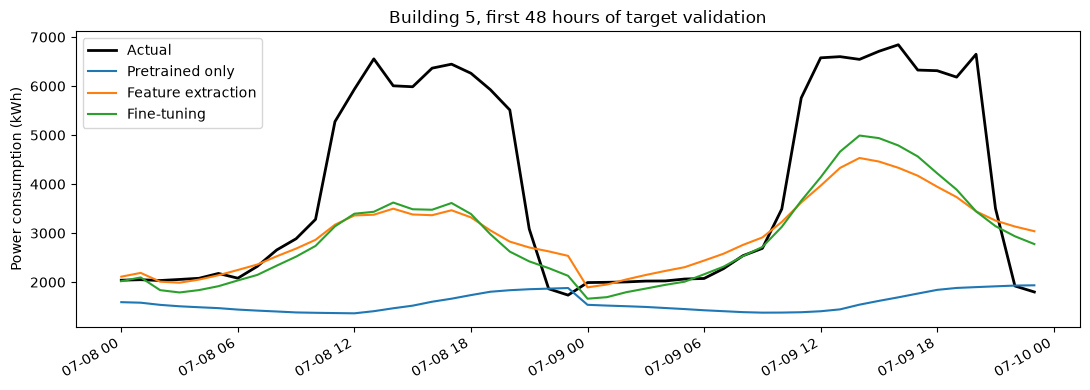

In [6]:
models = {"Pretrained only": pretrained,
          "Feature extraction": feature_model, "Fine-tuning": fine_model}
scores = target_scores(models)
print(scores.round(6).to_string(index=False))

pred_table = pd.DataFrame({"time": target_valid["time"].iloc[:5].to_numpy(),
                           "actual_kWh": target_valid[target].iloc[:5].to_numpy()})
pred_kwh_all = {}
for name, params in models.items():
    pred_kwh_all[name] = predict_scaled(X_valid, params).ravel() * y_std + y_mean
    pred_table[name] = pred_kwh_all[name][:5]
print()
print(pred_table.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(target_valid["time"].iloc[:48], target_valid[target].iloc[:48], label="Actual", color="black", linewidth=2)
for name in models:
    ax.plot(target_valid["time"].iloc[:48], pred_kwh_all[name][:48], label=name)
ax.set_ylabel("Power consumption (kWh)")
ax.set_title("Building 5, first 48 hours of target validation")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

#### 답변

**Q1. 세 모델의 대상 검증 MSE는 각각 얼마이며, 이번 실행에서는 어느 단계가 가장 낮나요?**

| 모델 | 대상 학습 MSE | 대상 검증 MSE |
|---|---:|---:|
| Pretrained only | 6.295834 | 7.568610 |
| Feature extraction | 1.318850 | 2.346366 |
| Fine-tuning | 1.088650 | **2.239531** |

- 이번 실행에서는 **Fine-tuning**의 검증 MSE가 가장 낮습니다.

**Q2. Source에서 이미 학습한 모델인데도 바로 5번 건물에 적용하면 오차가 클 수 있는 이유는 무엇인가요? Fine-tuning은 언제나 더 좋은 결과를 만드나요?**

- 사전학습 모델은 평균 소비량이 약 1,488 kWh인 1~4번 건물에 맞춰져 있습니다. 5번 건물은 평균 약 2,842 kWh로 소비 수준이 크게 다르고, 연면적(205,884 m²)도 Source 건물들의 범위를 벗어납니다. 그래서 출력 수준이 맞지 않아 오차가 큽니다(검증 MSE 7.57).
- 언제나 그렇지는 않습니다. 대상 데이터가 너무 적거나 학습률·epoch가 맞지 않으면 은닉층이 과적합되어 Feature Extraction보다 나빠질 수도 있습니다. 이번에는 개선 폭도 2.346 → 2.240으로 크지 않습니다.

**Q3. 이 표만으로 '사전학습을 쓰면 처음부터 학습하는 것보다 항상 좋다'고 결론 내릴 수 있나요? 최종 테스트 성능을 측정한 실험인가요?**

- 결론 내릴 수 없습니다. 이번 비교에는 **처음부터 학습한 모델(Scratch)이 없습니다**. 또한 한 건물·한 기간·한 설정의 결과입니다(Scratch와의 비교는 6장 2강에서 다룹니다).
- 아닙니다. 대상 검증 데이터로 단계를 비교했을 뿐이며, 따로 남겨 둔 테스트 기간으로 평가하지 않았습니다.

---

## 기초 과제. 업데이트 범위만 바꾸어 확인하기

### 문제 3-1. 같은 출발점에서 동결 여부만 바꾸기

In [7]:
frozen_more, frozen_history = train_model(feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=False)
frozen_changes = parameter_changes(feature_model, frozen_more)
print(frozen_changes.round(6).to_string(index=False))
print()
homework_scores = target_scores({"Frozen continuation": frozen_more, "Fine-tuning": fine_model})
homework_scores["updated_params"] = [9, 65]
print(homework_scores.round(6).to_string(index=False))

parameter  count  max_abs_change
       W1     48        0.000000
       b1      8        0.000000
       W2      8        0.037881
       b2      1        0.003479

              model  target_train_mse  target_valid_mse  updated_params
Frozen continuation          1.305568          2.339512               9
        Fine-tuning          1.088650          2.239531              65


#### 답변

**Q1. 두 조건에서 같게 유지한 것과 다르게 설정한 것은 무엇인가요? 각각 몇 개의 파라미터를 업데이트하나요?**

- 같게 유지: 시작 모델(`feature_model`), 대상 학습 데이터, 추가 epoch(100), 학습률(0.003), 평가 데이터
- 다르게 설정: `train_backbone`(Frozen continuation은 False, Fine-tuning은 True)
- 업데이트 수: Frozen continuation **9개**(W2·b2), Fine-tuning **65개**(전체)

**Q2. Frozen continuation의 W1·b1은 바뀌었나요? 출력층의 업데이트가 있었는데도 여전히 특징 추출부가 고정된 방식인 이유는 무엇인가요?**

- 바뀌지 않았습니다. 변화 표에서 W1·b1의 최대 변화가 **0**입니다.
- 특징 추출부는 은닉층(W1·b1)입니다. 출력층(W2·b2)만 업데이트하고 은닉층은 그대로이므로 같은 입력에서 같은 특징 H를 만들고, 그 위의 출력층만 학습하는 Feature Extraction 방식이 유지됩니다.

**Q3. 두 조건의 검증 손실 중 어느 것이 낮나요? 결과와 한계를 포함하여 2~3문장으로 설명하세요.**

- Fine-tuning의 검증 MSE(**2.239531**)가 Frozen continuation(**2.339512**)보다 약 0.10 낮습니다. 같은 출발점·학습률·epoch에서 은닉층까지 조정하자 5번 건물에 더 맞는 특징을 만들 수 있었다고 볼 수 있습니다. 다만 한 건물·한 주의 검증 결과이고 반복 실험도 하지 않았으므로, 다른 건물·기간·설정에서도 같은 결과가 나온다고 일반화할 수는 없습니다.

---

## 실습 마무리

### 마무리 1. 사전학습과 전달

- `initial`(무작위 초기값, 학습 없음) → `pretrained`(Source 1~4번 건물로 65개 모두 학습) → `feature_model`(Target Train으로 출력층 9개만 학습, 은닉층 고정) → `fine_model`(Target Train으로 65개 모두 작은 학습률로 추가 학습)
- Source에서 Target으로 전달한 것은 **학습된 은닉층 파라미터 W1·b1**(입력을 특징으로 바꾸는 방법)입니다. 출력층은 새로 초기화했고, Source 데이터 자체는 전달하지 않았습니다.

### 마무리 2. 특징과 파라미터

- X_train (168, 6) → H (168, 8) → 최종 예측 (168, 1)
- W1 6 × 8 = 48개, b1 8개, W2 8 × 1 = 8개, b2 1개 → 전체 **65개**(은닉층 56개 + 출력층 9개)
- H의 8개 특징은 입력 6개(기온·습도·시간·요일·연면적·냉방면적)를 은닉 뉴런마다 다른 가중치로 조합하고 Tanh를 적용한 **내부 표현**이며, 각각이 특정 물리량을 뜻하지는 않습니다.

### 마무리 3. 동결의 의미

- W1·b1·H가 모두 같아도, 그 H에 곱하는 **W2·b2가 학습으로 바뀌었기** 때문에 예측(H @ W2 + b2)이 달라집니다.
- "동결하면 은닉층을 생략한다"는 틀린 설명입니다. 은닉층은 순전파에서 계속 계산되며, 동결은 **업데이트만 하지 않는다**는 뜻입니다.

### 마무리 4. 미세조정의 출발점

- `feature_model`은 사전학습 특징과 대상 건물에 맞춘 출력층을 모두 갖고 있어, 큰 오차 없이 은닉층을 조금씩 다듬을 수 있는 좋은 출발점입니다.
- 작은 학습률(0.003)은 사전학습 특징을 크게 망가뜨리지 않고, 적은 데이터에 과적합되지 않도록 조금씩 조정하기 위해서입니다.
- 학습률 0.003과 `train_backbone=False`는 다릅니다. 학습률은 **얼마나 크게** 바꿀지, `train_backbone`은 은닉층을 **바꿀지 말지**를 정합니다.

### 마무리 5. 성능과 단위

- 대상 검증 MSE: Pretrained only 7.568610 > Feature extraction 2.346366 > Fine-tuning 2.239531. 이번 결과에서는 Fine-tuning이 가장 낮습니다.
- 이 MSE는 Source 기준으로 표준화된 전력소비량의 평균 제곱 오차이므로 kWh 단위의 평균 오차가 아닙니다(예: √2.24 × 814 ≈ 1,218 kWh가 RMSE에 해당). 또 168시간 전체의 평균이므로 모든 시간에서 같은 순서라는 뜻도 아닙니다. 실제로 검증 처음 5시간 중 02~04시에는 Feature extraction의 예측(2,010·1,989·2,052 kWh)이 Fine-tuning(1,837·1,789·1,838 kWh)보다 실제값(2,033·2,055·2,079 kWh)에 더 가까웠습니다.
- 검증 데이터로 비교한 결과이며, 별도의 최종 테스트 성능이 아닙니다.

### 마무리 6. 비교 조건과 핵심 정리

- 과제에서 같게 유지: 시작 모델, 대상 데이터, 학습률 0.003, 100 epoch / 바꾼 것: 은닉층 업데이트 여부
- **Pretrained Model**: 관련된 다른 데이터(1~4번 건물)로 미리 학습을 마친 모델입니다.
- **Feature Extraction**: 사전학습 은닉층을 고정해 특징을 만들고, 그 위의 출력층만 새 데이터로 학습하는 방식입니다.
- **Fine-tuning**: 사전학습된 파라미터에서 출발해, 은닉층까지 새 데이터로 작은 폭으로 추가 조정하는 방식입니다.